
# 06. SHAP Explainability and Interpretation

## Project
Dynamic and Explainable Credit Risk Early-Warning System with Portfolio Stress Testing

## Objective
This notebook develops an explainability framework for the selected Histogram Gradient Boosting model used to predict six-month forward-looking delinquency among currently current mortgage loans.

The analysis uses SHAP (SHapley Additive exPlanations) to investigate how model input features contribute to predicted delinquency probabilities.

## Research objectives

1. Identify the features that contribute most to model predictions.
2. Understand the direction and magnitude of feature contributions.
3. Explain individual loan-level risk predictions.
4. Validate that SHAP explanations are consistent with the saved model's predictions.

## Methodological controls

- Use the previously trained and selected HGB model.
- Preserve the original 129-feature training order.
- Use training-period observations as the SHAP background.
- Use validation-period observations for explanations.
- Do not use the test set for explainer selection or tuning.
- Do not modify or retrain the existing model.

## Expected outputs

- Global SHAP feature importance.
- SHAP summary visualisation.
- Feature-level contribution analysis.
- Individual loan explanations.
- Saved SHAP values and reproducible outputs.
  

In [1]:

# ============================================================
# SECTION 1: IMPORTS AND PROJECT CONFIGURATION
# ============================================================

from pathlib import Path
import json
import gc
import warnings

import numpy as np
import pandas as pd
import duckdb
import joblib
import shap
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

# Project directory
PROJECT_DIR = Path(
    r"C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning"
)

# Main directories
MODELS_DIR = PROJECT_DIR / "models"

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

PREPROCESSING_DIR = (
    PROCESSED_DIR / "model_preprocessing"
)

TRANSFORMED_DIR = (
    PREPROCESSING_DIR / "transformed_datasets"
)

NOTEBOOK_OUTPUT_DIR = (
    PROCESSED_DIR / "shap_analysis"
)

FIGURES_DIR = PROJECT_DIR / "figures" / "shap"

REPORTS_DIR = PROJECT_DIR / "reports"

# Create output directories
NOTEBOOK_OUTPUT_DIR.mkdir(
    parents=True, exist_ok=True
)

FIGURES_DIR.mkdir(
    parents=True, exist_ok=True
)

# Input files
HGB_MODEL_FILE = (
    MODELS_DIR / "hist_gradient_boosting_baseline.joblib"
)

TRAIN_FILE = (
    TRANSFORMED_DIR / "train_transformed.parquet"
)

VALIDATION_FILE = (
    TRANSFORMED_DIR / "validation_transformed.parquet"
)

PARAM_FILE = (
    PREPROCESSING_DIR /
    "training_preprocessing_parameters.json"
)

print("PROJECT:", PROJECT_DIR)
print("SHAP VERSION:", shap.__version__)
print("PANDAS VERSION:", pd.__version__)
print("NUMPY VERSION:", np.__version__)
print("DUCKDB VERSION:", duckdb.__version__)
print("PROJECT CONFIGURATION INITIALISED")
  

PROJECT: C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning
SHAP VERSION: 0.54.1
PANDAS VERSION: 3.0.3
NUMPY VERSION: 2.4.6
DUCKDB VERSION: 1.5.5
PROJECT CONFIGURATION INITIALISED


In [2]:

# ============================================================
# SECTION 2: FILE AND MODEL VERIFICATION
# ============================================================

required_files = {
    "HGB model": HGB_MODEL_FILE,
    "Training dataset": TRAIN_FILE,
    "Validation dataset": VALIDATION_FILE,
    "Preprocessing parameters": PARAM_FILE
}

for name, path in required_files.items():
    print(
        f"{name:30} :",
        "PASS" if path.exists() else "MISSING"
    )

assert all(
    path.exists() for path in required_files.values()
), "One or more required files are missing."

# Load the selected HGB model
hgb_model = joblib.load(HGB_MODEL_FILE)

print("\nSELECTED MODEL")
print(type(hgb_model))
print("Input features:", hgb_model.n_features_in_)
print("Iterations:", hgb_model.n_iter_)
print("Classes:", hgb_model.classes_)

assert hgb_model.n_features_in_ == 129

print("\nMODEL VERIFICATION PASSED")
  

HGB model                      : PASS
Training dataset               : PASS
Validation dataset             : PASS
Preprocessing parameters       : PASS

SELECTED MODEL
<class 'sklearn.ensemble._hist_gradient_boosting.gradient_boosting.HistGradientBoostingClassifier'>
Input features: 129
Iterations: 200
Classes: [0 1]

MODEL VERIFICATION PASSED


In [3]:

# ============================================================
# SECTION 3: FEATURE SCHEMA VERIFICATION
# ============================================================

con = duckdb.connect()

train_schema = con.execute(
    f"DESCRIBE SELECT * FROM read_parquet('{TRAIN_FILE.as_posix()}')"
).fetchdf()

validation_schema = con.execute(
    f"DESCRIBE SELECT * FROM read_parquet('{VALIDATION_FILE.as_posix()}')"
).fetchdf()

con.close()

CORE_COLUMNS = [
    "loan_id",
    "reporting_date",
    "target_6m"
]

train_columns = train_schema["column_name"].tolist()

validation_columns = (
    validation_schema["column_name"].tolist()
)

predictor_columns = [
    col for col in train_columns
    if col not in CORE_COLUMNS
]

model_feature_columns = list(
    hgb_model.feature_names_in_
)

assert train_columns == validation_columns
assert predictor_columns == model_feature_columns
assert len(predictor_columns) == 129

print("Train/validation schema match: PASS")
print("Exact HGB feature order match: PASS")
print("Predictor count:", len(predictor_columns))
  

Train/validation schema match: PASS
Exact HGB feature order match: PASS
Predictor count: 129



## 4. SHAP Background and Explanation Sample Preparation

SHAP explanations require a background dataset that represents the reference distribution of model inputs.

In this study:

- Background observations are selected from the training period (2018–2022).
- Explanation observations are selected from the validation period (2023).
- The validation sample contains both positive and negative target observations.
- All samples retain the exact 129-feature order used during model training.

A small pilot sample is used initially to assess computational feasibility and verify prediction consistency.


In [4]:

# ============================================================
# SECTION 4: SHAP SAMPLE PREPARATION
# ============================================================

import duckdb
import pandas as pd
import numpy as np

# Exact model feature order
predictor_columns = list(hgb_model.feature_names_in_)

assert len(predictor_columns) == 129

# Quote feature names safely for SQL
feature_sql = ", ".join(
    '"' + col.replace('"', '""') + '"'
    for col in predictor_columns
)

con = duckdb.connect()

# ------------------------------------------------------------
# 1. Training background sample
# ------------------------------------------------------------

background_query = f"""
SELECT {feature_sql}
FROM read_parquet('{TRAIN_FILE.as_posix()}')
ORDER BY hash(loan_id, reporting_date)
LIMIT 50
"""

background_df = con.execute(
    background_query
).fetchdf()

# ------------------------------------------------------------
# 2. Validation non-events
# ------------------------------------------------------------

non_event_query = f"""
SELECT loan_id, reporting_date, target_6m, {feature_sql}
FROM read_parquet('{VALIDATION_FILE.as_posix()}')
WHERE target_6m = 0
ORDER BY hash(loan_id, reporting_date)
LIMIT 10
"""

validation_non_events = con.execute(
    non_event_query
).fetchdf()

# ------------------------------------------------------------
# 3. Validation events
# ------------------------------------------------------------

event_query = f"""
SELECT loan_id, reporting_date, target_6m, {feature_sql}
FROM read_parquet('{VALIDATION_FILE.as_posix()}')
WHERE target_6m = 1
ORDER BY hash(loan_id, reporting_date)
LIMIT 10
"""

validation_events = con.execute(
    event_query
).fetchdf()

con.close()

# Combine validation samples
explanation_df = pd.concat(
    [validation_non_events, validation_events],
    ignore_index=True
)

# Preserve identifiers and target separately
X_background = background_df[
    predictor_columns
].astype(np.float32)

X_explain = explanation_df[
    predictor_columns
].astype(np.float32)

# ------------------------------------------------------------
# 4. Save samples
# ------------------------------------------------------------

background_df.to_parquet(
    NOTEBOOK_OUTPUT_DIR / "shap_background_sample.parquet",
    index=False
)

explanation_df.to_parquet(
    NOTEBOOK_OUTPUT_DIR / "shap_validation_pilot_sample.parquet",
    index=False
)

# ------------------------------------------------------------
# 5. Validation checks
# ------------------------------------------------------------

print("BACKGROUND SHAPE:", X_background.shape)
print("EXPLANATION SHAPE:", X_explain.shape)

print("\nTARGET DISTRIBUTION:")
print(
    explanation_df["target_6m"]
    .value_counts()
    .sort_index()
)

print("\nFEATURE ORDER CHECK:")
print(
    list(X_background.columns)
    == list(hgb_model.feature_names_in_)
)

print(
    list(X_explain.columns)
    == list(hgb_model.feature_names_in_)
)

print("\nFINITE VALUE CHECK:")
print(
    "Background:",
    np.isfinite(X_background.to_numpy()).all()
)

print(
    "Explanation:",
    np.isfinite(X_explain.to_numpy()).all()
)

assert X_background.shape == (50, 129)
assert X_explain.shape == (20, 129)
assert explanation_df["target_6m"].value_counts().to_dict() == {
    0: 10,
    1: 10
}

assert np.isfinite(X_background.to_numpy()).all()
assert np.isfinite(X_explain.to_numpy()).all()

print("\nSHAP PILOT SAMPLE PREPARATION: PASS")


BACKGROUND SHAPE: (50, 129)
EXPLANATION SHAPE: (20, 129)

TARGET DISTRIBUTION:
target_6m
0    10
1    10
Name: count, dtype: int64

FEATURE ORDER CHECK:
True
True

FINITE VALUE CHECK:
Background: True
Explanation: True

SHAP PILOT SAMPLE PREPARATION: PASS


In [5]:

# ============================================================
# SECTION 5: BASELINE PREDICTION VERIFICATION
# ============================================================

pilot_probabilities = hgb_model.predict_proba(
    X_explain
)[:, 1]

prediction_check = explanation_df[
    ["loan_id", "reporting_date", "target_6m"]
].copy()

prediction_check["predicted_probability"] = (
    pilot_probabilities
)

prediction_check["predicted_class_050"] = (
    pilot_probabilities >= 0.50
).astype(int)

print("PREDICTION COUNT:", len(pilot_probabilities))

print("\nPREDICTION RANGE:")
print("Minimum:", pilot_probabilities.min())
print("Maximum:", pilot_probabilities.max())

print("\nPREDICTION SUMMARY:")
print(
    prediction_check[
        "predicted_probability"
    ].describe()
)

print("\nPREDICTION SAMPLE:")
print(prediction_check.head(10).to_string(index=False))

assert len(pilot_probabilities) == 20
assert np.isfinite(pilot_probabilities).all()
assert (
    (pilot_probabilities >= 0) &
    (pilot_probabilities <= 1)
).all()

prediction_check.to_csv(
    NOTEBOOK_OUTPUT_DIR / "shap_pilot_predictions.csv",
    index=False
)

print("\nBASELINE PREDICTION VERIFICATION: PASS")


PREDICTION COUNT: 20

PREDICTION RANGE:
Minimum: 0.10783544749407933
Maximum: 0.9239206299123275

PREDICTION SUMMARY:
count    20.000000
mean      0.370733
std       0.281014
min       0.107835
25%       0.180769
50%       0.255324
75%       0.435185
max       0.923921
Name: predicted_probability, dtype: float64

PREDICTION SAMPLE:
     loan_id reporting_date  target_6m  predicted_probability  predicted_class_050
829299954309     2023-03-01          0               0.278064                    0
374796337748     2023-08-01          0               0.150184                    0
396544817189     2023-08-01          0               0.133535                    0
741240195000     2023-05-01          0               0.188133                    0
264268493225     2023-02-01          0               0.151119                    0
934806094365     2023-06-01          0               0.203172                    0
278444512003     2023-05-01          0               0.349958                    0
73


## 5. SHAP Explainer Compatibility Test

The selected model is a scikit-learn Histogram Gradient Boosting Classifier.

A model-agnostic PermutationExplainer is used to explain the positive-class predicted probability.

The explainer uses:
- Training observations as the background reference.
- Validation observations as the explanation inputs.
- The original 129-feature model input order.
- A controlled evaluation budget for the initial compatibility test.

The pilot explains two validation observations before any larger computation is attempted.

SHAP values are interpreted in probability units because the explained model output is the predicted probability of the six-month delinquency event.


In [6]:

# ============================================================
# SECTION 5: PERMUTATION SHAP EXPLAINER PILOT
# ============================================================

import shap
import numpy as np
import pandas as pd

# 1. Confirm model feature order
predictor_columns = list(hgb_model.feature_names_in_)

assert X_background.shape[1] == 129
assert X_explain.shape[1] == 129

# 2. Create model prediction function
# Always return probability for class 1.

def predict_positive(data):

    if isinstance(data, pd.DataFrame):
        model_input = data[predictor_columns]
    else:
        model_input = pd.DataFrame(
            data,
            columns=predictor_columns
        )

    return hgb_model.predict_proba(
        model_input
    )[:, 1]


# 3. Create independent background masker
masker = shap.maskers.Independent(
    X_background,
    max_samples=50
)

# 4. Create permutation explainer
explainer = shap.PermutationExplainer(
    predict_positive,
    masker,
    feature_names=predictor_columns,
    seed=42
)

# 5. Explain only two observations initially
PILOT_ROWS = 2

MAX_EVALS = (
    2 * len(predictor_columns) + 1
)

print("FEATURE COUNT:", len(predictor_columns))
print("MAXIMUM EVALUATIONS:", MAX_EVALS)
print("PILOT OBSERVATIONS:", PILOT_ROWS)

pilot_explanation = explainer(
    X_explain.iloc[:PILOT_ROWS],
    max_evals=MAX_EVALS
)

# 6. Extract SHAP values
pilot_shap_values = np.asarray(
    pilot_explanation.values
)

pilot_base_values = np.asarray(
    pilot_explanation.base_values
)

print("\nSHAP OUTPUT SHAPE:", pilot_shap_values.shape)
print("BASE VALUES SHAPE:", pilot_base_values.shape)

print("\nSHAP EXPLAINER PILOT COMPLETED")


FEATURE COUNT: 129
MAXIMUM EVALUATIONS: 259
PILOT OBSERVATIONS: 2

SHAP OUTPUT SHAPE: (2, 129)
BASE VALUES SHAPE: (2,)

SHAP EXPLAINER PILOT COMPLETED


In [7]:

# ============================================================
# SECTION 6: SHAP ADDITIVITY AND PREDICTION RECONCILIATION
# ============================================================

# Actual model probabilities
actual_probabilities = predict_positive(
    X_explain.iloc[:PILOT_ROWS]
)

# Reconstructed probabilities from SHAP
reconstructed_probabilities = (
    pilot_base_values.reshape(-1)
    + pilot_shap_values.sum(axis=1)
)

# Absolute difference
absolute_errors = np.abs(
    actual_probabilities - reconstructed_probabilities
)

reconciliation = pd.DataFrame({
    "actual_probability": actual_probabilities,
    "shap_reconstructed_probability": reconstructed_probabilities,
    "absolute_error": absolute_errors
})

print(reconciliation.to_string(index=False))

print("\nMAXIMUM ABSOLUTE ERROR:",
      absolute_errors.max())

print(
    "ADDITIVITY CHECK:",
    np.allclose(
        actual_probabilities,
        reconstructed_probabilities,
        atol=1e-5,
        rtol=1e-5
    )
)

assert np.allclose(
    actual_probabilities,
    reconstructed_probabilities,
    atol=1e-5,
    rtol=1e-5
), "SHAP additivity check failed."

print("\nSHAP PILOT VALIDATION: PASS")


 actual_probability  shap_reconstructed_probability  absolute_error
           0.278064                        0.278064    1.665335e-16
           0.150184                        0.150184    1.387779e-16

MAXIMUM ABSOLUTE ERROR: 1.6653345369377348e-16
ADDITIVITY CHECK: True

SHAP PILOT VALIDATION: PASS



## 7. Main SHAP Analysis

The pilot demonstrated that the PermutationExplainer can explain the selected HGB model and reconstruct its predicted probabilities.

The main analysis uses a reproducible sample from the 2023 validation period. Unlike the balanced pilot, this sample preserves the natural target distribution as closely as possible.

Three permutation cycles are initially used to obtain more stable feature attribution estimates than a single permutation cycle.

The analysis calculates:
- SHAP values for each observation and feature.
- Mean absolute SHAP importance.
- Mean signed SHAP contribution.
- Global feature rankings.

The initial sample is an exploratory computational analysis. Its size and stability will be assessed before final research claims are made.


In [8]:

# ============================================================
# SECTION 7A: REPRESENTATIVE VALIDATION SAMPLE
# ============================================================

import time

GLOBAL_SAMPLE_SIZE = 100

feature_sql = ", ".join(
    '"' + col.replace('"', '""') + '"'
    for col in predictor_columns
)

con = duckdb.connect()

global_sample_query = f"""
SELECT
    loan_id,
    reporting_date,
    target_6m,
    {feature_sql}
FROM read_parquet('{VALIDATION_FILE.as_posix()}')
ORDER BY hash(loan_id, reporting_date)
LIMIT {GLOBAL_SAMPLE_SIZE}
"""

global_explanation_df = con.execute(
    global_sample_query
).fetchdf()

con.close()

X_global = global_explanation_df[
    predictor_columns
].astype(np.float32)

y_global = global_explanation_df[
    "target_6m"
].astype(int)

print("GLOBAL SAMPLE SHAPE:", X_global.shape)

print("\nTARGET DISTRIBUTION:")
print(y_global.value_counts().sort_index())

print("\nEVENT RATE:", round(y_global.mean(), 5))

assert X_global.shape == (100, 129)
assert np.isfinite(X_global.to_numpy()).all()
assert list(X_global.columns) == predictor_columns

global_explanation_df.to_parquet(
    NOTEBOOK_OUTPUT_DIR /
    "shap_global_validation_sample.parquet",
    index=False
)

print("\nREPRESENTATIVE SAMPLE PREPARATION: PASS")


GLOBAL SAMPLE SHAPE: (100, 129)

TARGET DISTRIBUTION:
target_6m
0    98
1     2
Name: count, dtype: int64

EVENT RATE: 0.02

REPRESENTATIVE SAMPLE PREPARATION: PASS


In [9]:

# ============================================================
# SECTION 7B: MAIN SHAP VALUE CALCULATION
# ============================================================

import time
import numpy as np
import pandas as pd

# Three permutation cycles
PERMUTATION_CYCLES = 3

MAX_EVALS_GLOBAL = (
    2 * len(predictor_columns) *
    PERMUTATION_CYCLES + 1
)

print("Observations:", len(X_global))
print("Features:", len(predictor_columns))
print("Permutation cycles:", PERMUTATION_CYCLES)
print("Maximum evaluations per observation:", MAX_EVALS_GLOBAL)

start_time = time.time()

global_shap_explanation = explainer(
    X_global,
    max_evals=MAX_EVALS_GLOBAL
)

elapsed_seconds = time.time() - start_time

global_shap_values = np.asarray(
    global_shap_explanation.values
)

global_base_values = np.asarray(
    global_shap_explanation.base_values
)

print("\nSHAP CALCULATION COMPLETED")
print("SHAP shape:", global_shap_values.shape)
print("Base values shape:", global_base_values.shape)
print("Execution time (minutes):", round(elapsed_seconds / 60, 2))

assert global_shap_values.shape == (100, 129)
assert np.isfinite(global_shap_values).all()

print("\nGLOBAL SHAP CALCULATION: PASS")


Observations: 100
Features: 129
Permutation cycles: 3
Maximum evaluations per observation: 775


PermutationExplainer explainer: 101it [00:32,  2.18it/s]                         


SHAP CALCULATION COMPLETED
SHAP shape: (100, 129)
Base values shape: (100,)
Execution time (minutes): 0.54

GLOBAL SHAP CALCULATION: PASS


In [10]:

# ============================================================
# SECTION 7C: GLOBAL SHAP ADDITIVITY VALIDATION
# ============================================================

global_actual_probabilities = predict_positive(
    X_global
)

global_reconstructed_probabilities = (
    global_base_values.reshape(-1)
    + global_shap_values.sum(axis=1)
)

global_absolute_errors = np.abs(
    global_actual_probabilities
    - global_reconstructed_probabilities
)

global_reconciliation = pd.DataFrame({
    "actual_probability": global_actual_probabilities,
    "shap_reconstructed_probability":
        global_reconstructed_probabilities,
    "absolute_error": global_absolute_errors
})

print(global_reconciliation.head(10).to_string(index=False))

print("\nMAXIMUM ABSOLUTE ERROR:",
      global_absolute_errors.max())

print(
    "ADDITIVITY CHECK:",
    np.allclose(
        global_actual_probabilities,
        global_reconstructed_probabilities,
        atol=1e-5,
        rtol=1e-5
    )
)

assert np.allclose(
    global_actual_probabilities,
    global_reconstructed_probabilities,
    atol=1e-5,
    rtol=1e-5
)

global_reconciliation.to_csv(
    NOTEBOOK_OUTPUT_DIR /
    "shap_global_reconciliation.csv",
    index=False
)

print("\nGLOBAL SHAP RECONCILIATION: PASS")


 actual_probability  shap_reconstructed_probability  absolute_error
           0.278064                        0.278064    1.665335e-16
           0.150184                        0.150184    1.110223e-16
           0.133535                        0.133535    8.326673e-17
           0.188133                        0.188133    0.000000e+00
           0.151119                        0.151119    1.110223e-16
           0.203172                        0.203172    5.551115e-17
           0.349958                        0.349958    1.110223e-16
           0.158680                        0.158680    8.326673e-17
           0.386454                        0.386454    1.110223e-16
           0.107835                        0.107835    5.551115e-17

MAXIMUM ABSOLUTE ERROR: 1.1102230246251565e-15
ADDITIVITY CHECK: True

GLOBAL SHAP RECONCILIATION: PASS



## 9. Expanded Global SHAP Analysis

The initial 100-observation analysis established computational compatibility and successful probability reconstruction.

To improve the stability of global feature-importance estimates, the analysis is expanded to 1,000 randomly selected observations from the validation period.

The sample retains the natural validation-period class distribution. Three permutation cycles are used for feature attribution.

The expanded analysis is used for exploratory global interpretation. Feature-importance stability will be assessed before final conclusions are reported.


In [11]:

# ============================================================
# SECTION 9A: EXPANDED VALIDATION SAMPLE
# ============================================================

EXPANDED_SAMPLE_SIZE = 1000

feature_sql = ", ".join(
    '"' + col.replace('"', '""') + '"'
    for col in predictor_columns
)

con = duckdb.connect()

expanded_query = f"""
SELECT
    loan_id,
    reporting_date,
    target_6m,
    {feature_sql}
FROM read_parquet('{VALIDATION_FILE.as_posix()}')
ORDER BY hash(loan_id, reporting_date)
LIMIT {EXPANDED_SAMPLE_SIZE}
"""

expanded_df = con.execute(
    expanded_query
).fetchdf()

con.close()

X_expanded = expanded_df[
    predictor_columns
].astype(np.float32)

y_expanded = expanded_df["target_6m"].astype(int)

print("EXPANDED SAMPLE:", X_expanded.shape)

print("\nTARGET DISTRIBUTION:")
print(y_expanded.value_counts().sort_index())

print("\nEVENT RATE:", y_expanded.mean())

assert X_expanded.shape == (1000, 129)
assert np.isfinite(X_expanded.to_numpy()).all()
assert list(X_expanded.columns) == predictor_columns

expanded_df.to_parquet(
    NOTEBOOK_OUTPUT_DIR /
    "shap_expanded_validation_sample.parquet",
    index=False
)

print("\nEXPANDED SAMPLE VALIDATION: PASS")


EXPANDED SAMPLE: (1000, 129)

TARGET DISTRIBUTION:
target_6m
0    965
1     35
Name: count, dtype: int64

EVENT RATE: 0.035

EXPANDED SAMPLE VALIDATION: PASS


In [12]:

# ============================================================
# SECTION 9B: EXPANDED SHAP CALCULATION
# ============================================================

import time
import numpy as np

EXPANDED_CYCLES = 3

EXPANDED_MAX_EVALS = (
    2 * len(predictor_columns) *
    EXPANDED_CYCLES + 1
)

print("Observations:", len(X_expanded))
print("Features:", len(predictor_columns))
print("Maximum evaluations per observation:",
      EXPANDED_MAX_EVALS)

start_time = time.time()

expanded_shap_explanation = explainer(
    X_expanded,
    max_evals=EXPANDED_MAX_EVALS
)

expanded_elapsed = time.time() - start_time

expanded_shap_values = np.asarray(
    expanded_shap_explanation.values
)

expanded_base_values = np.asarray(
    expanded_shap_explanation.base_values
)

print("\nSHAP SHAPE:", expanded_shap_values.shape)
print("BASE SHAPE:", expanded_base_values.shape)
print("TIME (MINUTES):", round(expanded_elapsed / 60, 2))

assert expanded_shap_values.shape == (1000, 129)
assert np.isfinite(expanded_shap_values).all()

print("\nEXPANDED SHAP CALCULATION: PASS")


Observations: 1000
Features: 129
Maximum evaluations per observation: 775


PermutationExplainer explainer: 1001it [17:18,  1.05s/it]                          


SHAP SHAPE: (1000, 129)
BASE SHAPE: (1000,)
TIME (MINUTES): 17.32

EXPANDED SHAP CALCULATION: PASS


In [13]:

# ============================================================
# SECTION 9C: EXPANDED SHAP RECONCILIATION
# ============================================================

expanded_actual = predict_positive(X_expanded)

expanded_reconstructed = (
    expanded_base_values.reshape(-1)
    + expanded_shap_values.sum(axis=1)
)

expanded_errors = np.abs(
    expanded_actual - expanded_reconstructed
)

print("MAXIMUM ABSOLUTE ERROR:",
      expanded_errors.max())

print("MEAN ABSOLUTE ERROR:",
      expanded_errors.mean())

expanded_additivity_pass = np.allclose(
    expanded_actual,
    expanded_reconstructed,
    atol=1e-5,
    rtol=1e-5
)

print("ADDITIVITY CHECK:", expanded_additivity_pass)

assert expanded_additivity_pass

print("\nEXPANDED SHAP VALIDATION: PASS")


MAXIMUM ABSOLUTE ERROR: 1.2212453270876722e-15
MEAN ABSOLUTE ERROR: 1.698224894042255e-16
ADDITIVITY CHECK: True

EXPANDED SHAP VALIDATION: PASS


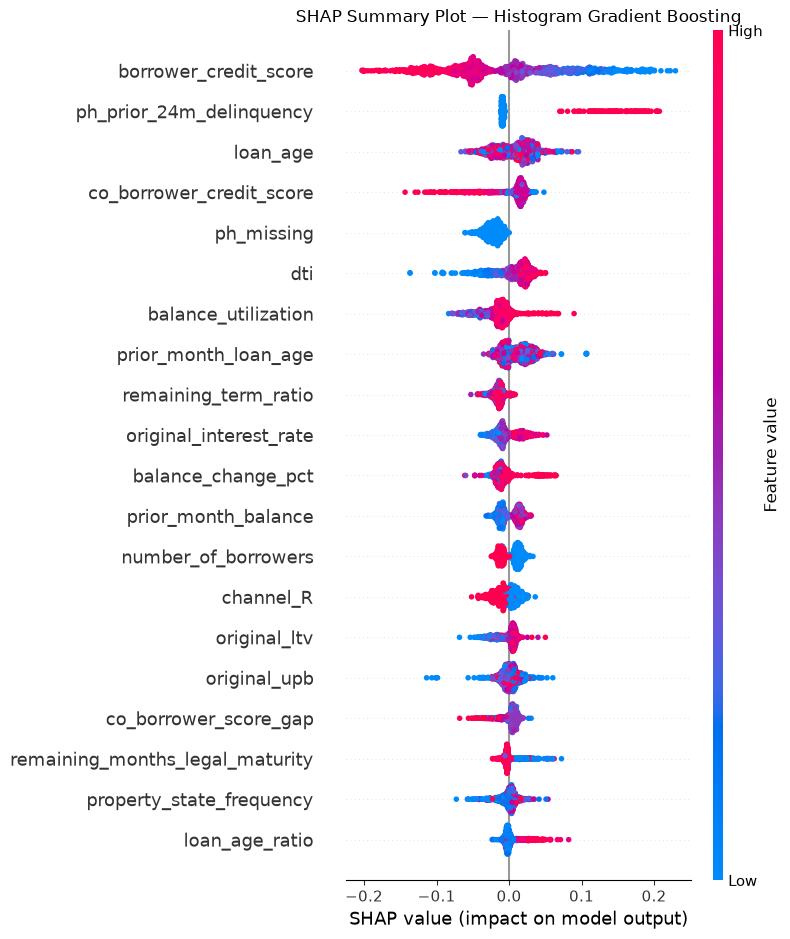

In [14]:

# ============================================================
# SECTION 10A: SHAP SUMMARY PLOT
# ============================================================

plt.figure(figsize=(12, 9))

shap.summary_plot(
    expanded_shap_values,
    X_expanded,
    feature_names=predictor_columns,
    max_display=20,
    show=False
)

plt.title(
    "SHAP Summary Plot — Histogram Gradient Boosting"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "shap_summary_1000.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



## 11. Saving and Reproducibility

The calculated SHAP values, expected values, feature names and validation sample identifiers are saved as separate artifacts.

This preserves the explainability results and allows subsequent analysis without recalculating SHAP values.

The saved artifacts correspond to the selected HGB model and the 1,000-observation validation sample.


In [15]:

# ============================================================
# SECTION 11A: SAVE EXPANDED SHAP ARTIFACTS
# ============================================================

import json
import numpy as np

# Save SHAP values
np.save(
    NOTEBOOK_OUTPUT_DIR / "shap_values_1000.npy",
    expanded_shap_values
)

# Save base values
np.save(
    NOTEBOOK_OUTPUT_DIR / "shap_base_values_1000.npy",
    expanded_base_values
)

# Save exact feature order
with open(
    NOTEBOOK_OUTPUT_DIR / "shap_feature_names.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(predictor_columns, f, indent=2)

# Save sample identifiers and actual outcomes
expanded_df[
    ["loan_id", "reporting_date", "target_6m"]
].to_csv(
    NOTEBOOK_OUTPUT_DIR / "shap_sample_identifiers_1000.csv",
    index=False
)

# Save run metadata
metadata = {
    "model": "HistGradientBoostingClassifier",
    "model_artifact": "hist_gradient_boosting_baseline.joblib",
    "explainer": "PermutationExplainer",
    "explained_output": "positive_class_probability",
    "background_observations": 50,
    "explanation_observations": 1000,
    "features": 129,
    "permutation_cycles": 3,
    "maximum_evaluations_per_observation": 775,
    "validation_period": "2023-01 to 2023-12",
    "background_period": "2018-01 to 2022-12",
    "max_additivity_error": float(expanded_errors.max())
}

with open(
    NOTEBOOK_OUTPUT_DIR / "shap_run_metadata.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metadata, f, indent=2)

print("SHAP ARTIFACTS SAVED")

for path in sorted(NOTEBOOK_OUTPUT_DIR.iterdir()):
    if path.is_file() and path.name.startswith("shap_"):
        print(path.name, round(path.stat().st_size / 1024, 2), "KB")


SHAP ARTIFACTS SAVED
shap_background_sample.parquet 94.51 KB
shap_base_values_1000.npy 7.94 KB
shap_expanded_validation_sample.parquet 177.54 KB
shap_feature_names.json 4.25 KB
shap_global_reconciliation.csv 6.04 KB
shap_global_validation_sample.parquet 102.55 KB
shap_pilot_predictions.csv 1.02 KB
shap_run_metadata.json 0.5 KB
shap_sample_identifiers_1000.csv 26.4 KB
shap_validation_pilot_sample.parquet 92.91 KB
shap_values_1000.npy 1007.94 KB


In [16]:

# ============================================================
# SECTION 12: NUMERICAL GLOBAL FEATURE IMPORTANCE
# ============================================================

# Recalculate to ensure results are based on expanded SHAP values
expanded_importance = pd.DataFrame({
    "feature": predictor_columns,
    "mean_absolute_shap": np.mean(
        np.abs(expanded_shap_values), axis=0
    ),
    "mean_signed_shap": np.mean(
        expanded_shap_values, axis=0
    )
})

expanded_importance = (
    expanded_importance
    .sort_values("mean_absolute_shap", ascending=False)
    .reset_index(drop=True)
)

expanded_importance.insert(
    0, "rank", np.arange(1, len(expanded_importance) + 1)
)

expanded_importance.to_csv(
    NOTEBOOK_OUTPUT_DIR / "shap_global_importance_1000.csv",
    index=False
)

print("TOP 20 GLOBAL SHAP FEATURES")
display(expanded_importance.head(20).round(6))


TOP 20 GLOBAL SHAP FEATURES


,rank,feature,mean_absolute_shap,mean_signed_shap
0,1,borrower_credit_score,0.070547,-0.007157
1,2,ph_prior_24m_delinquency,0.024357,0.008596
2,3,loan_age,0.022720,0.008491
3,4,co_borrower_credit_score,0.021557,0.004185
4,5,ph_missing,0.021470,-0.021470
5,6,dti,0.021345,0.005089
6,7,balance_utilization,0.020135,-0.016263
7,8,prior_month_loan_age,0.017013,0.010142
8,9,remaining_term_ratio,0.015017,-0.014817
9,10,original_interest_rate,0.014561,-0.003278


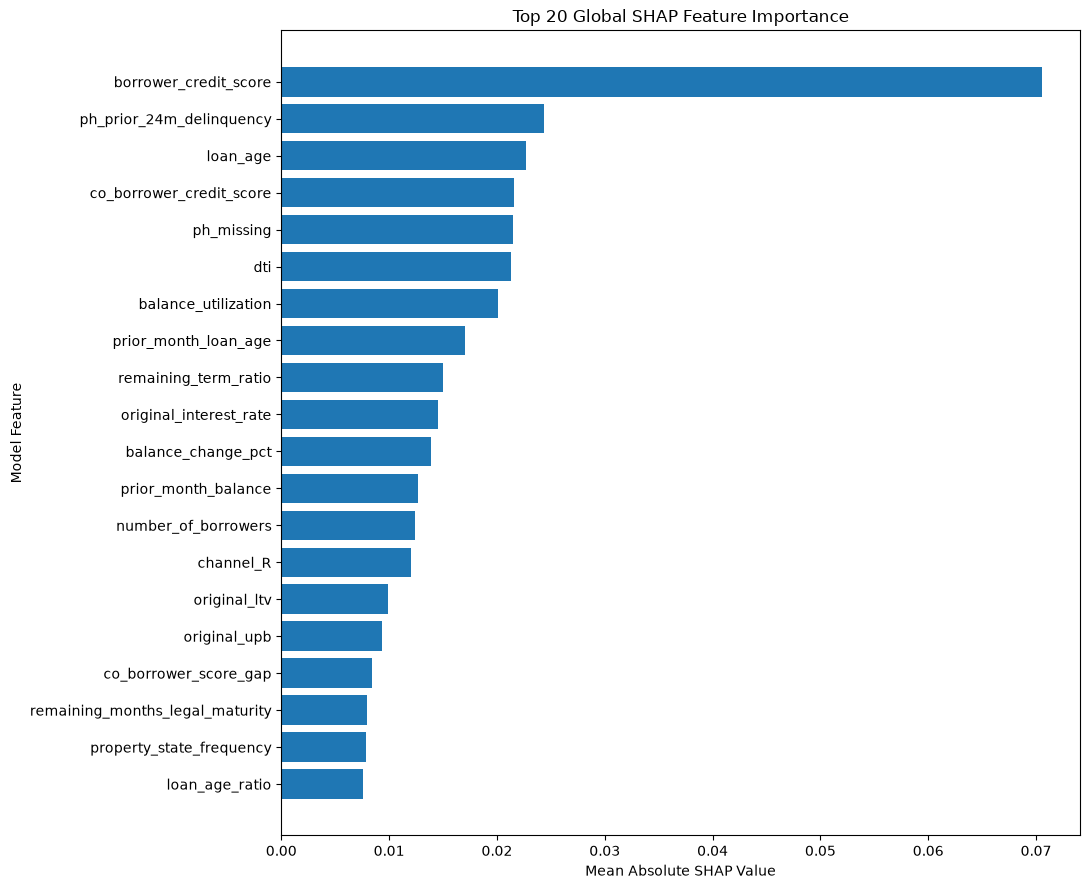

In [17]:

# ============================================================
# SECTION 12A: GLOBAL SHAP BAR CHART
# ============================================================

top20 = expanded_importance.head(20).sort_values(
    "mean_absolute_shap",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 9))

ax.barh(
    top20["feature"],
    top20["mean_absolute_shap"]
)

ax.set_xlabel("Mean Absolute SHAP Value")
ax.set_ylabel("Model Feature")
ax.set_title("Top 20 Global SHAP Feature Importance")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "shap_global_importance_1000.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



## 13. Individual Feature Effect Analysis

Feature-level SHAP dependence plots are used to examine how individual feature values relate to their contributions to predicted delinquency probability.

The analysis focuses initially on borrower credit score, prior payment delinquency, loan age and debt-to-income ratio.

These plots describe the learned model relationships and should not be interpreted as causal effects.


<Figure size 800x600 with 0 Axes>

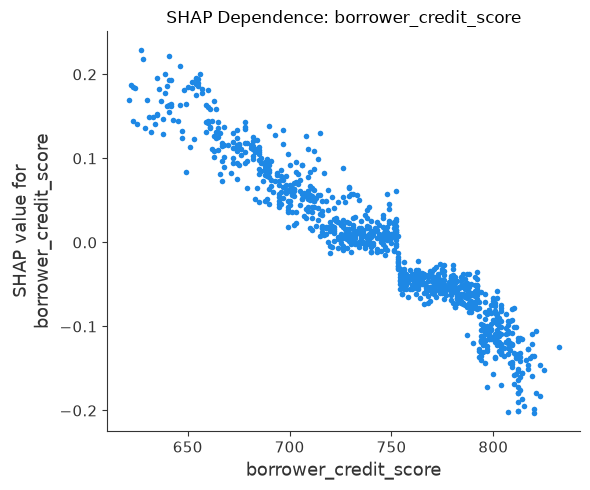

<Figure size 800x600 with 0 Axes>

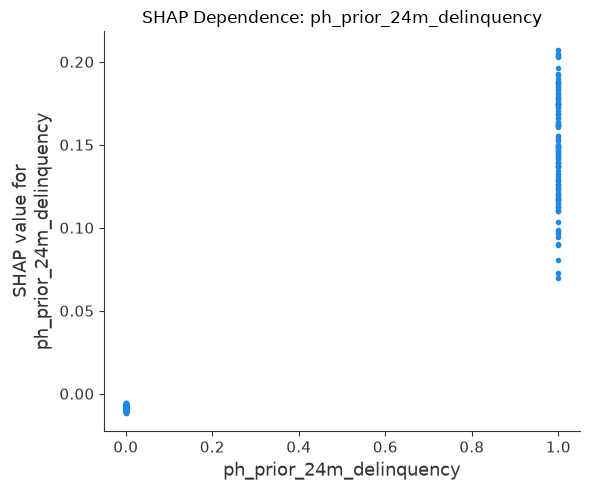

<Figure size 800x600 with 0 Axes>

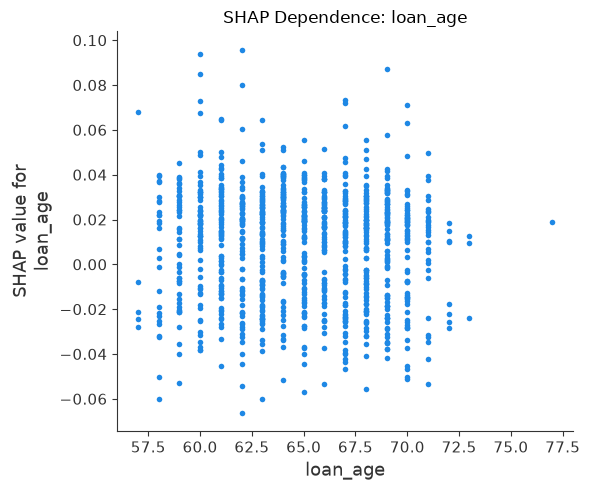

<Figure size 800x600 with 0 Axes>

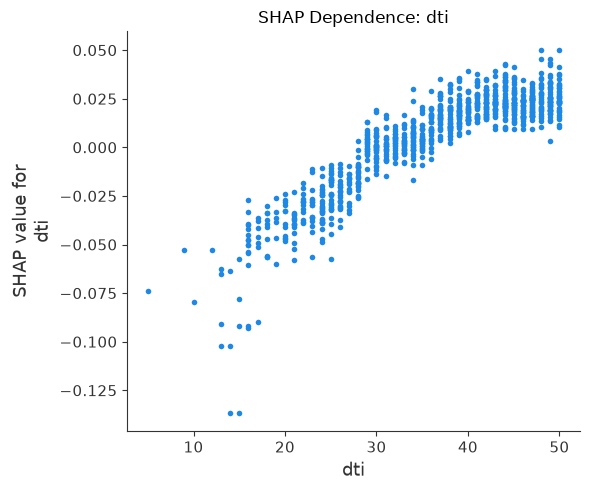

In [18]:

# ============================================================
# SECTION 13A: SHAP FEATURE DEPENDENCE PLOTS
# ============================================================

selected_features = [
    "borrower_credit_score",
    "ph_prior_24m_delinquency",
    "loan_age",
    "dti"
]

for feature in selected_features:

    if feature not in predictor_columns:
        print("SKIPPED:", feature)
        continue

    plt.figure(figsize=(8, 6))

    shap.dependence_plot(
        feature,
        expanded_shap_values,
        X_expanded,
        interaction_index=None,
        show=False
    )

    plt.title(f"SHAP Dependence: {feature}")
    plt.tight_layout()

    safe_name = feature.replace("/", "_")

    plt.savefig(
        FIGURES_DIR / f"shap_dependence_{safe_name}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()



## 14. Individual Loan-Level SHAP Explanation

A local explanation is generated for a validation observation with a high predicted delinquency probability.

The waterfall plot illustrates how individual feature contributions move the model output from its expected background prediction to the selected loan's predicted probability.

This provides an interpretable explanation of one model prediction, rather than a causal explanation of borrower behaviour.


SELECTED LOAN ID: 667728694608
REPORTING DATE: 2023-01-01 00:00:00
ACTUAL TARGET: 1
PREDICTED PROBABILITY: 0.9479055007852917


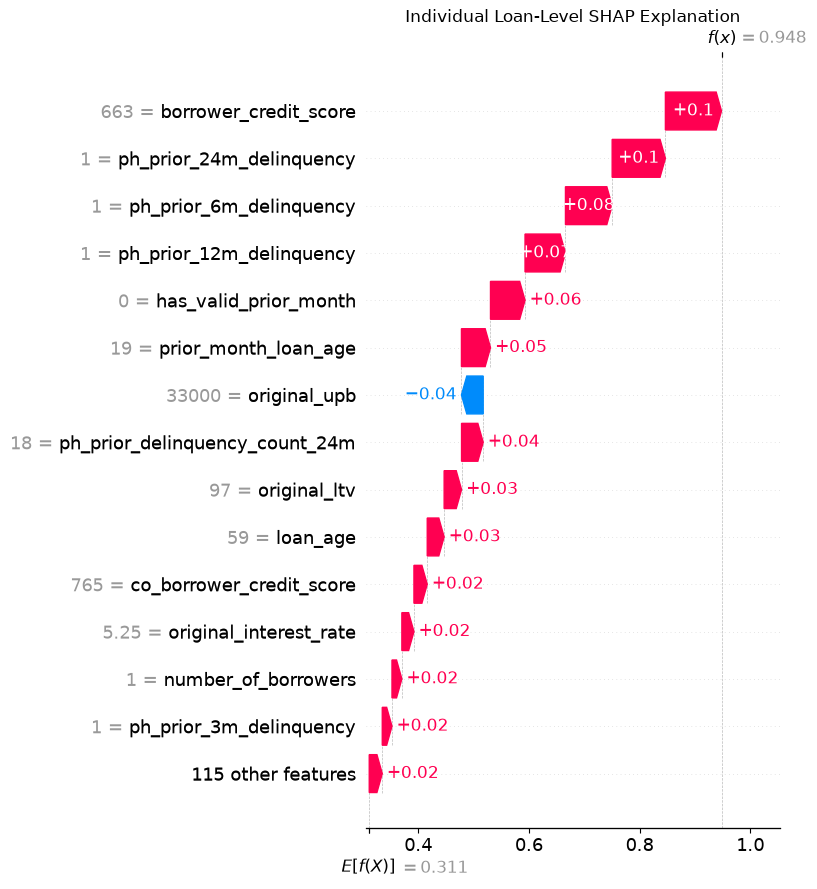

In [19]:

# ============================================================
# SECTION 14A: INDIVIDUAL LOAN EXPLANATION
# ============================================================

# Identify the highest predicted-risk observation
expanded_probabilities = predict_positive(X_expanded)

highest_risk_index = int(
    np.argmax(expanded_probabilities)
)

individual_probability = float(
    expanded_probabilities[highest_risk_index]
)

individual_row = expanded_df.iloc[highest_risk_index]

print("SELECTED LOAN ID:", individual_row["loan_id"])
print("REPORTING DATE:", individual_row["reporting_date"])
print("ACTUAL TARGET:", individual_row["target_6m"])
print("PREDICTED PROBABILITY:", individual_probability)

# Create SHAP Explanation object
individual_explanation = shap.Explanation(
    values=expanded_shap_values[highest_risk_index],
    base_values=expanded_base_values[highest_risk_index],
    data=X_expanded.iloc[highest_risk_index].to_numpy(),
    feature_names=predictor_columns
)

# Generate waterfall plot
plt.figure(figsize=(10, 8))

shap.plots.waterfall(
    individual_explanation,
    max_display=15,
    show=False
)

plt.title("Individual Loan-Level SHAP Explanation")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "shap_individual_high_risk_waterfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



## 15. Detailed Individual Loan Contribution Analysis

This section examines the individual SHAP contributions for the selected high-risk validation observation.

Features are ranked by their signed SHAP contributions to identify the strongest risk-increasing and risk-reducing factors.

The analysis also compares individual feature contributions with their global mean SHAP behaviour.


In [20]:

# ============================================================
# SECTION 15: INDIVIDUAL SHAP CONTRIBUTION TABLE
# ============================================================

# Recalculate selected observation index safely
expanded_probabilities = predict_positive(X_expanded)

highest_risk_index = int(
    np.argmax(expanded_probabilities)
)

individual_values = expanded_shap_values[
    highest_risk_index
]

individual_features = X_expanded.iloc[
    highest_risk_index
]

local_contribution_table = pd.DataFrame({
    "feature": predictor_columns,
    "feature_value": individual_features.values,
    "individual_shap": individual_values,
    "global_mean_absolute_shap":
        np.mean(np.abs(expanded_shap_values), axis=0),
    "global_mean_signed_shap":
        np.mean(expanded_shap_values, axis=0)
})

local_contribution_table = (
    local_contribution_table
    .sort_values(
        "individual_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

print("TOP 15 RISK-INCREASING FEATURES")
display(local_contribution_table.head(15).round(6))

print("\nTOP 15 RISK-REDUCING FEATURES")
display(
    local_contribution_table.tail(15)
    .sort_values("individual_shap")
    .round(6)
)

local_contribution_table.to_csv(
    NOTEBOOK_OUTPUT_DIR /
    "shap_individual_contribution_table.csv",
    index=False
)

print("\nINDIVIDUAL CONTRIBUTION TABLE SAVED")


TOP 15 RISK-INCREASING FEATURES


,feature,feature_value,individual_shap,global_mean_absolute_shap,global_mean_signed_shap
0,borrower_credit_score,663.0000,0.101411,0.070547,-0.007157
1,ph_prior_24m_delinquency,1.0000,0.096178,0.024357,0.008596
2,ph_prior_6m_delinquency,1.0000,0.084391,0.002660,0.002660
3,ph_prior_12m_delinquency,1.0000,0.073039,0.005894,0.001921
4,has_valid_prior_month,0.0000,0.062408,0.001564,-0.000349
5,prior_month_loan_age,19.0000,0.052478,0.017013,0.010142
6,ph_prior_delinquency_count_24m,18.0000,0.039089,0.002259,0.000242
7,original_ltv,97.0000,0.031471,0.009893,-0.002085
8,loan_age,59.0000,0.030528,0.022720,0.008491
9,co_borrower_credit_score,765.0000,0.024020,0.021557,0.004185



TOP 15 RISK-REDUCING FEATURES


,feature,feature_value,individual_shap,global_mean_absolute_shap,global_mean_signed_shap
128,original_upb,33000.000000,-0.039280,0.009363,0.001052
127,remaining_term_ratio,0.819444,-0.015127,0.015017,-0.014817
126,ph_prior_max_delinquency,3.000000,-0.013319,0.006027,-0.005268
125,ph_missing,0.000000,-0.011817,0.021470,-0.021470
124,current_actual_upb,30032.310547,-0.006558,0.006137,0.000281
123,balance_utilization,0.910070,-0.005789,0.020135,-0.016263
122,reporting_month,1.000000,-0.005753,0.003643,-0.002065
121,remaining_months_legal_maturity,301.000000,-0.004520,0.007906,0.001517
120,property_state_frequency,0.028613,-0.004114,0.007892,-0.000615
119,zip_code_short_frequency,0.000757,-0.001933,0.007252,0.002213



INDIVIDUAL CONTRIBUTION TABLE SAVED


In [21]:

# ============================================================
# SECTION 15A: HIGH-RISK FALSE-POSITIVE CASE STUDY
# ============================================================

case_summary = {
    "loan_id": str(
        expanded_df.iloc[highest_risk_index]["loan_id"]
    ),
    "reporting_date": str(
        expanded_df.iloc[highest_risk_index]["reporting_date"]
    ),
    "actual_target": int(
        expanded_df.iloc[highest_risk_index]["target_6m"]
    ),
    "predicted_probability": float(
        expanded_probabilities[highest_risk_index]
    ),
    "base_value": float(
        expanded_base_values[highest_risk_index]
    ),
    "classification_at_0_50": int(
        expanded_probabilities[highest_risk_index] >= 0.50
    ),
    "case_interpretation": (
        "False positive at 0.50 threshold"
        if (
            expanded_probabilities[highest_risk_index] >= 0.50
            and expanded_df.iloc[highest_risk_index]["target_6m"] == 0
        )
        else "Review classification and actual target"
    )
}

print(json.dumps(case_summary, indent=2))

with open(
    NOTEBOOK_OUTPUT_DIR /
    "shap_individual_case_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(case_summary, f, indent=2)


{
  "loan_id": "667728694608",
  "reporting_date": "2023-01-01 00:00:00",
  "actual_target": 1,
  "predicted_probability": 0.9479055007852917,
  "base_value": 0.31140080059162395,
  "classification_at_0_50": 1,
  "case_interpretation": "Review classification and actual target"
}


In [22]:

# ============================================================
# SECTION 15B: INDIVIDUAL CASE CONSISTENCY AUDIT
# ============================================================

idx = int(np.argmax(expanded_probabilities))

selected_row = expanded_df.iloc[idx]

selected_id = selected_row["loan_id"]
selected_date = pd.Timestamp(
    selected_row["reporting_date"]
)

print("SAMPLE INDEX:", idx)
print("LOAN ID:", selected_id)
print("REPORTING DATE:", selected_date)
print("TARGET IN EXPANDED DATA:", selected_row["target_6m"])
print("TARGET IN y_expanded:", y_expanded.iloc[idx])

print(
    "PREDICTION:",
    expanded_probabilities[idx]
)

print(
    "SHAP RECONSTRUCTED:",
    expanded_base_values[idx]
    + expanded_shap_values[idx].sum()
)

# Independently retrieve the original validation record
con = duckdb.connect()

source_check = con.execute(
    f"""
    SELECT loan_id, reporting_date, target_6m
    FROM read_parquet('{VALIDATION_FILE.as_posix()}')
    WHERE loan_id = ?
      AND CAST(reporting_date AS DATE) = ?
    """,
    [int(selected_id), selected_date.date()]
).fetchdf()

con.close()

print("\nORIGINAL VALIDATION RECORD:")
display(source_check)

assert len(source_check) == 1, (
    "Expected exactly one matching source observation."
)

assert int(source_check.iloc[0]["target_6m"]) == int(
    selected_row["target_6m"]
)

assert int(y_expanded.iloc[idx]) == int(
    selected_row["target_6m"]
)

print("\nCASE CONSISTENCY AUDIT: PASS")


SAMPLE INDEX: 507
LOAN ID: 667728694608
REPORTING DATE: 2023-01-01 00:00:00
TARGET IN EXPANDED DATA: 1
TARGET IN y_expanded: 1
PREDICTION: 0.9479055007852917
SHAP RECONSTRUCTED: 0.9479055007852912

ORIGINAL VALIDATION RECORD:


,loan_id,reporting_date,target_6m
0,667728694608,2023-01-01,1



CASE CONSISTENCY AUDIT: PASS


In [23]:
from pathlib import Path

print("SHAP DEPENDENCE PLOTS")

for feature in [
    "borrower_credit_score",
    "ph_prior_24m_delinquency",
    "loan_age",
    "dti"
]:
    path = FIGURES_DIR / f"shap_dependence_{feature}.png"

    print(
        feature,
        "| EXISTS:", path.exists(),
        "| PATH:", path
    )

SHAP DEPENDENCE PLOTS
borrower_credit_score | EXISTS: True | PATH: C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning\figures\shap\shap_dependence_borrower_credit_score.png
ph_prior_24m_delinquency | EXISTS: True | PATH: C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning\figures\shap\shap_dependence_ph_prior_24m_delinquency.png
loan_age | EXISTS: True | PATH: C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning\figures\shap\shap_dependence_loan_age.png
dti | EXISTS: True | PATH: C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning\figures\shap\shap_dependence_dti.png



 borrower_credit_score


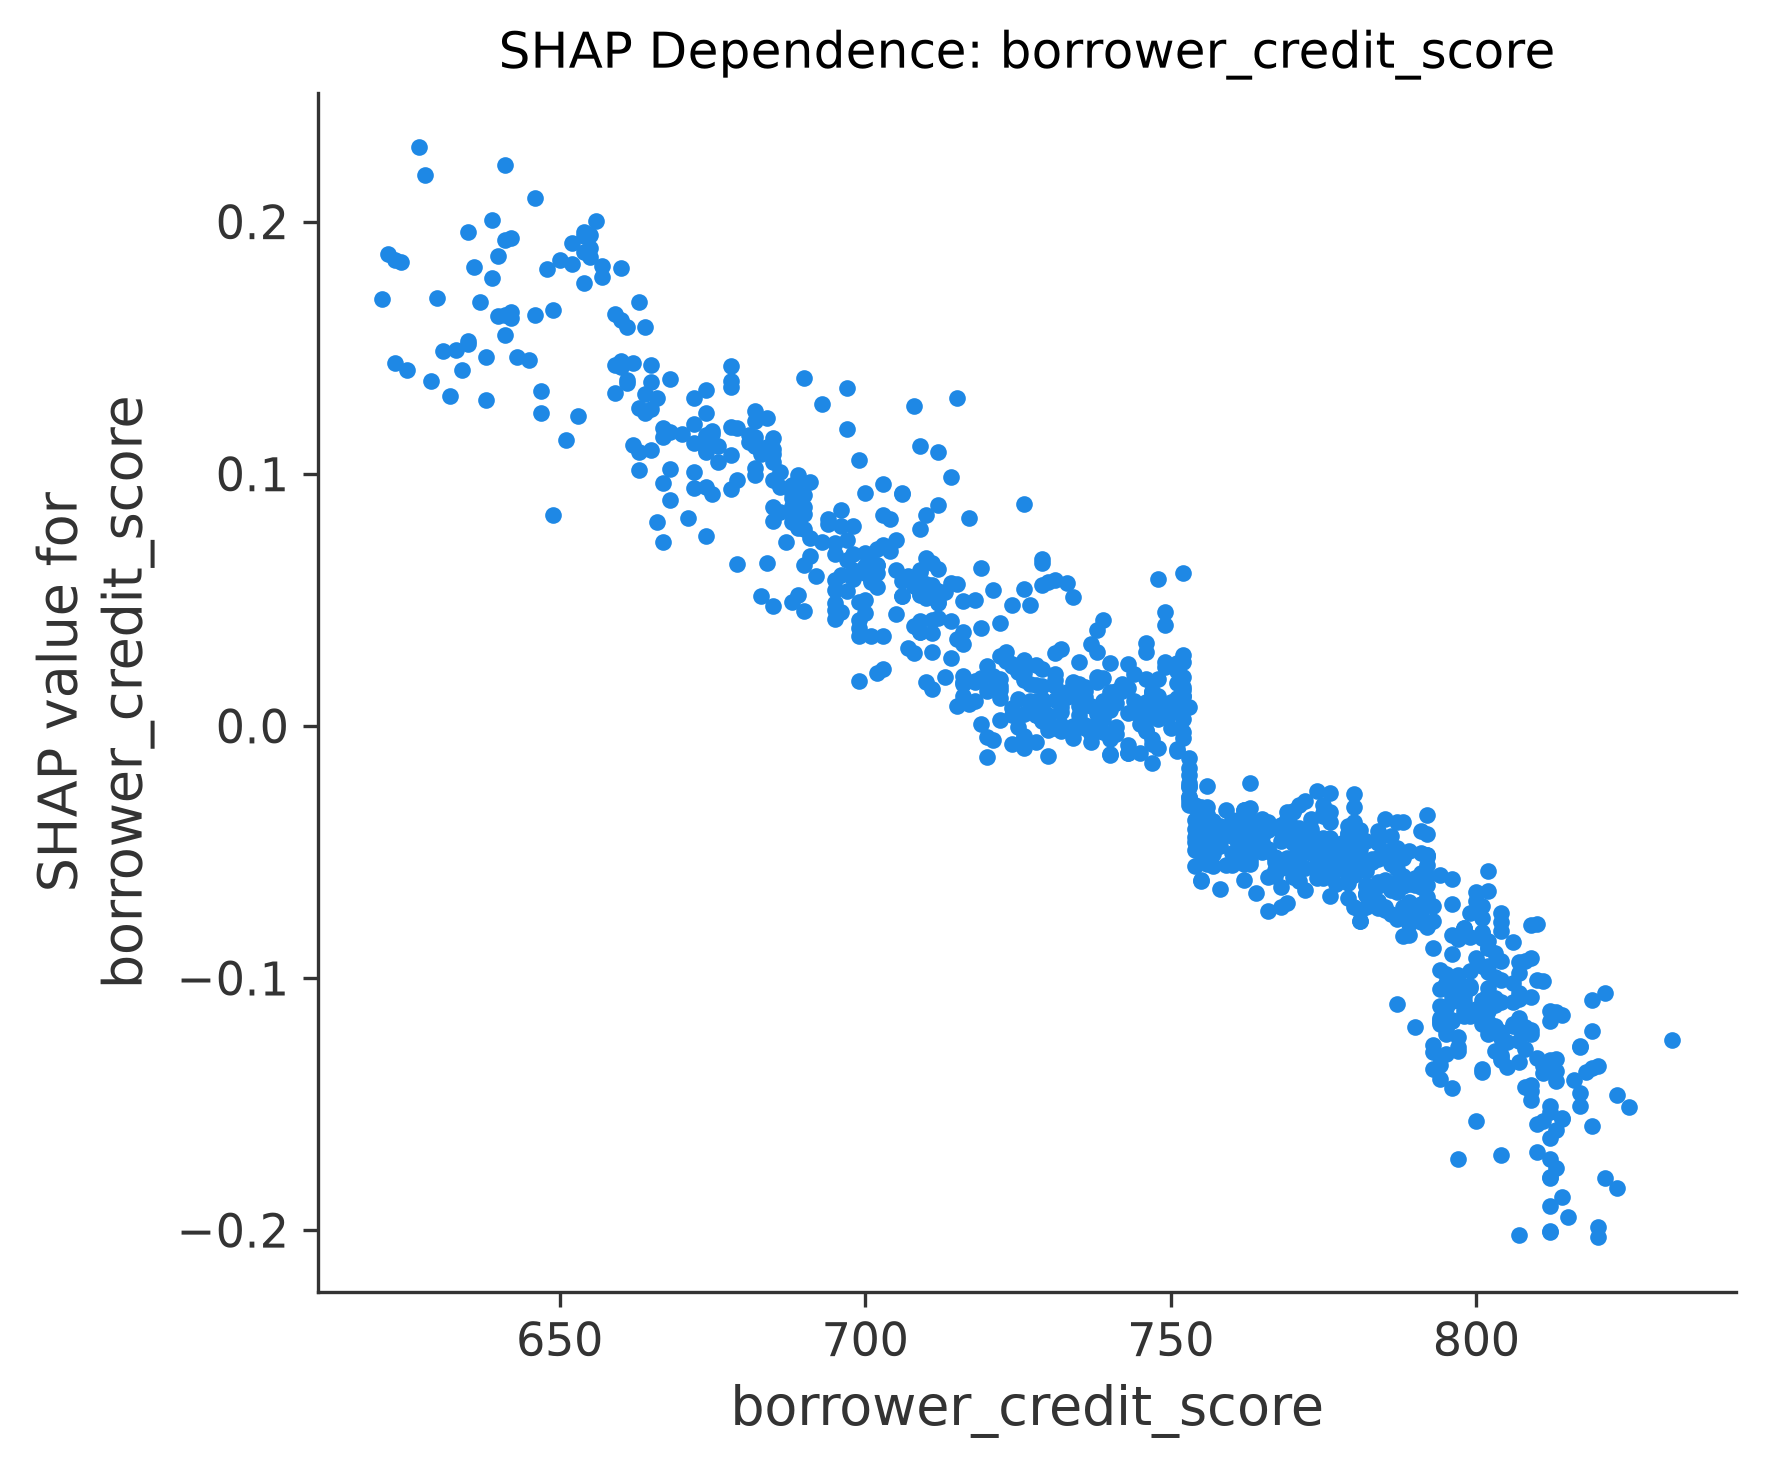


 ph_prior_24m_delinquency


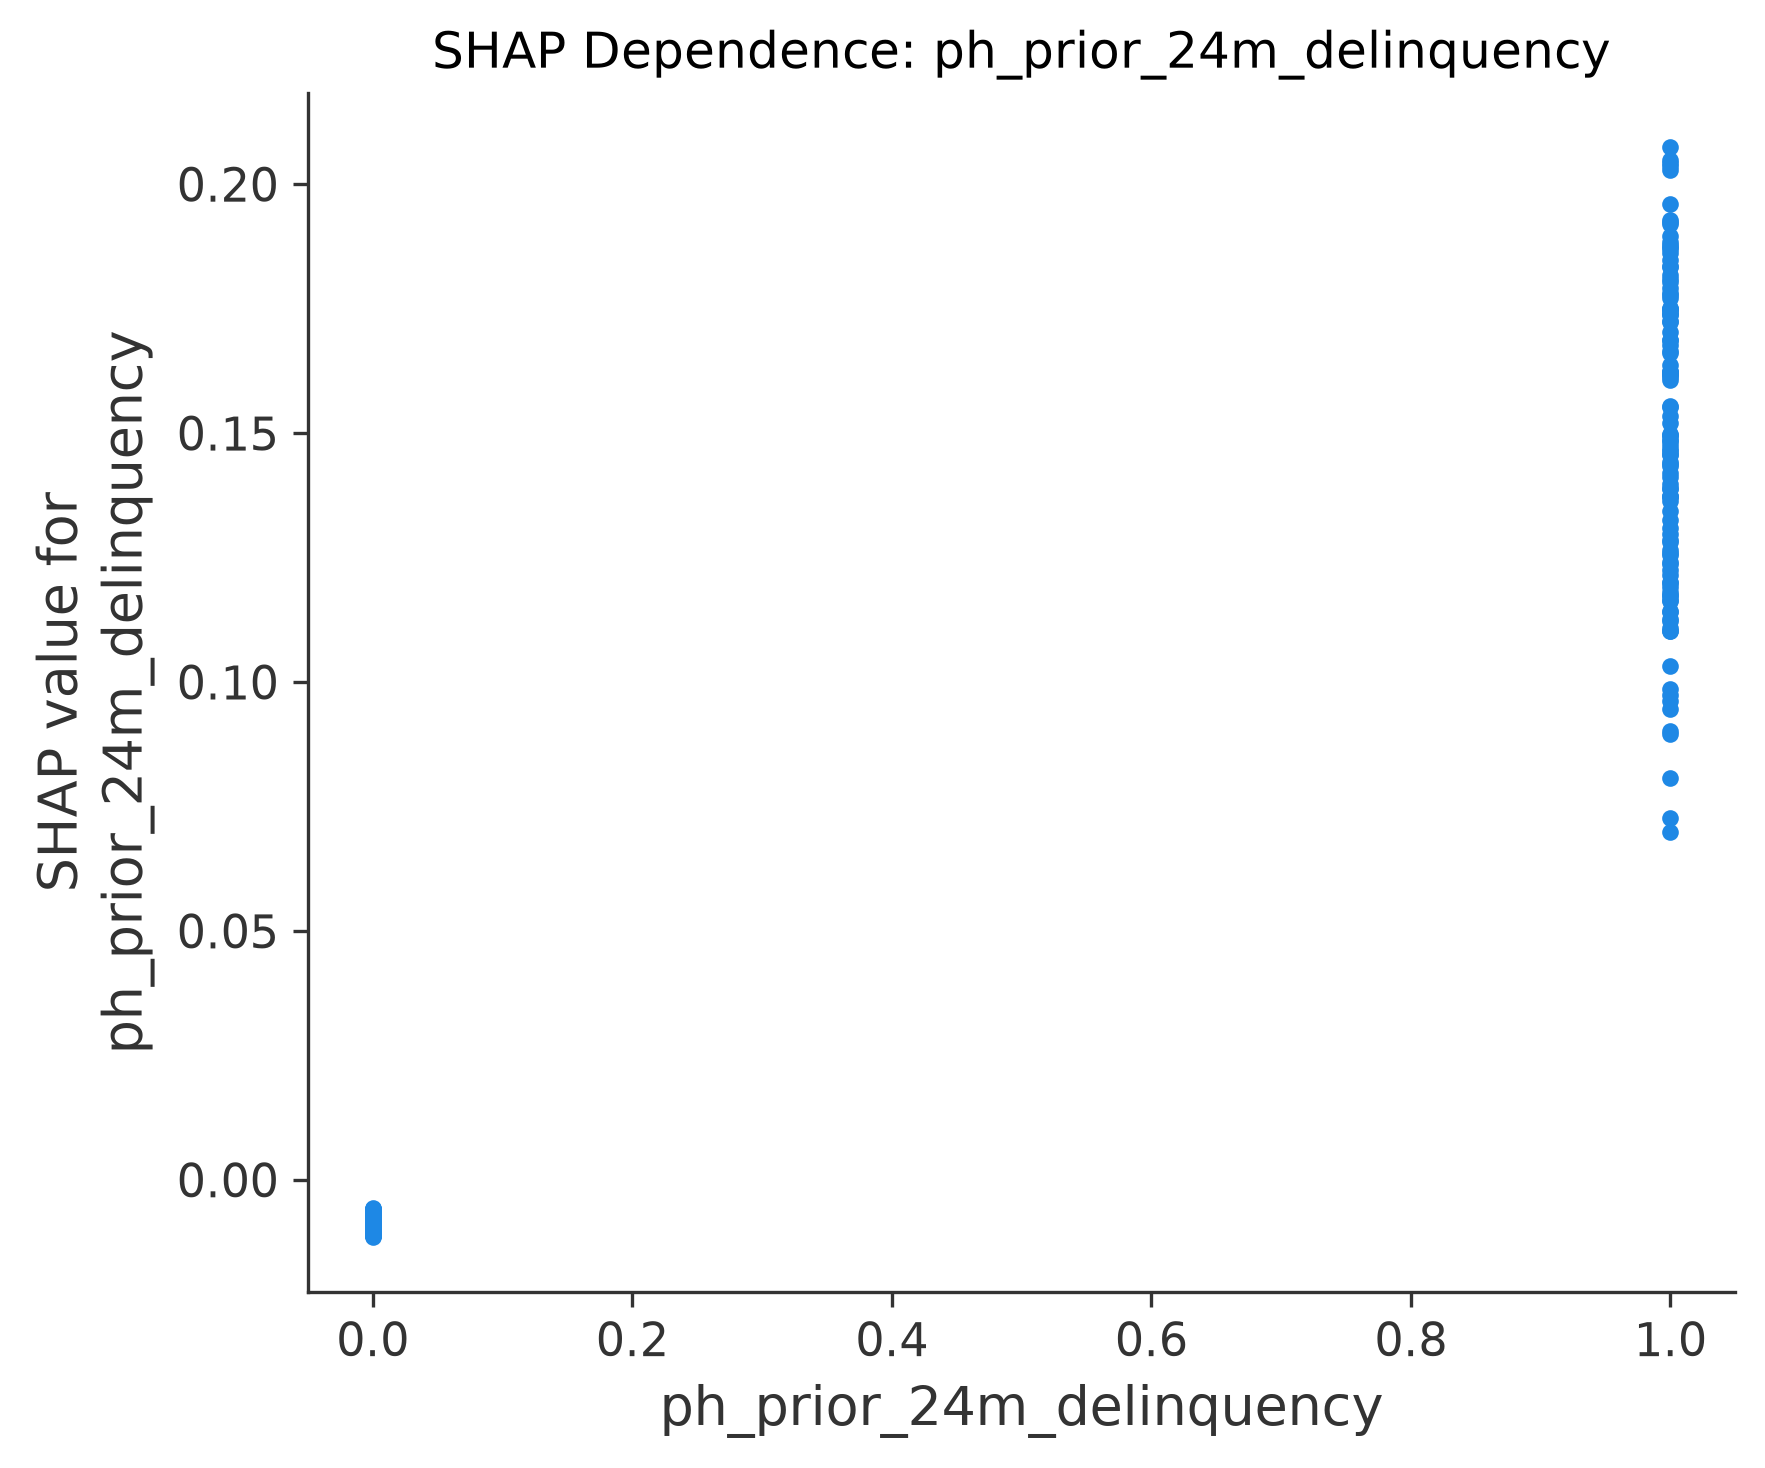


 loan_age


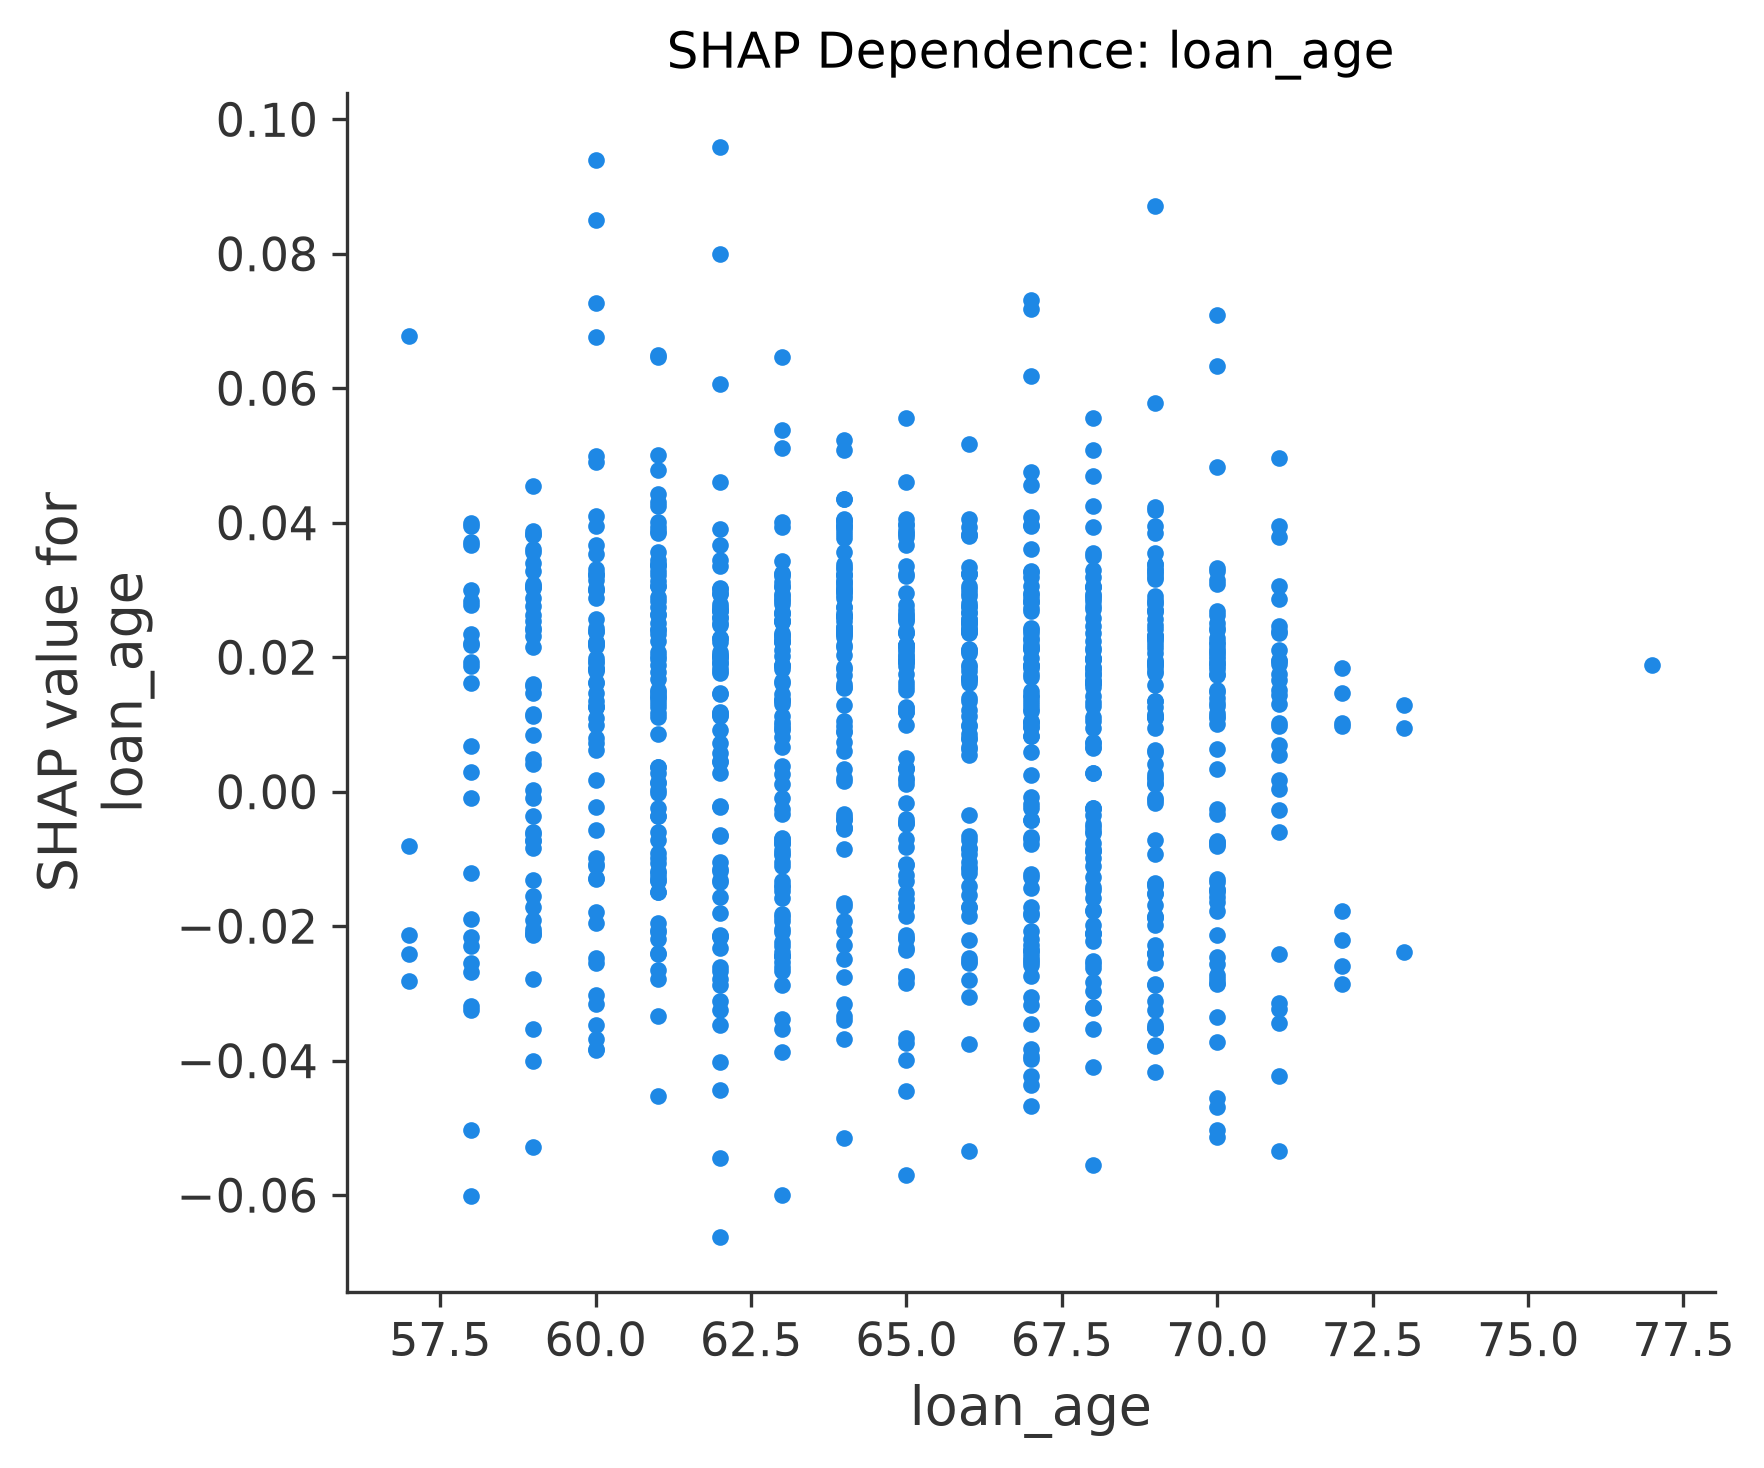


 dti


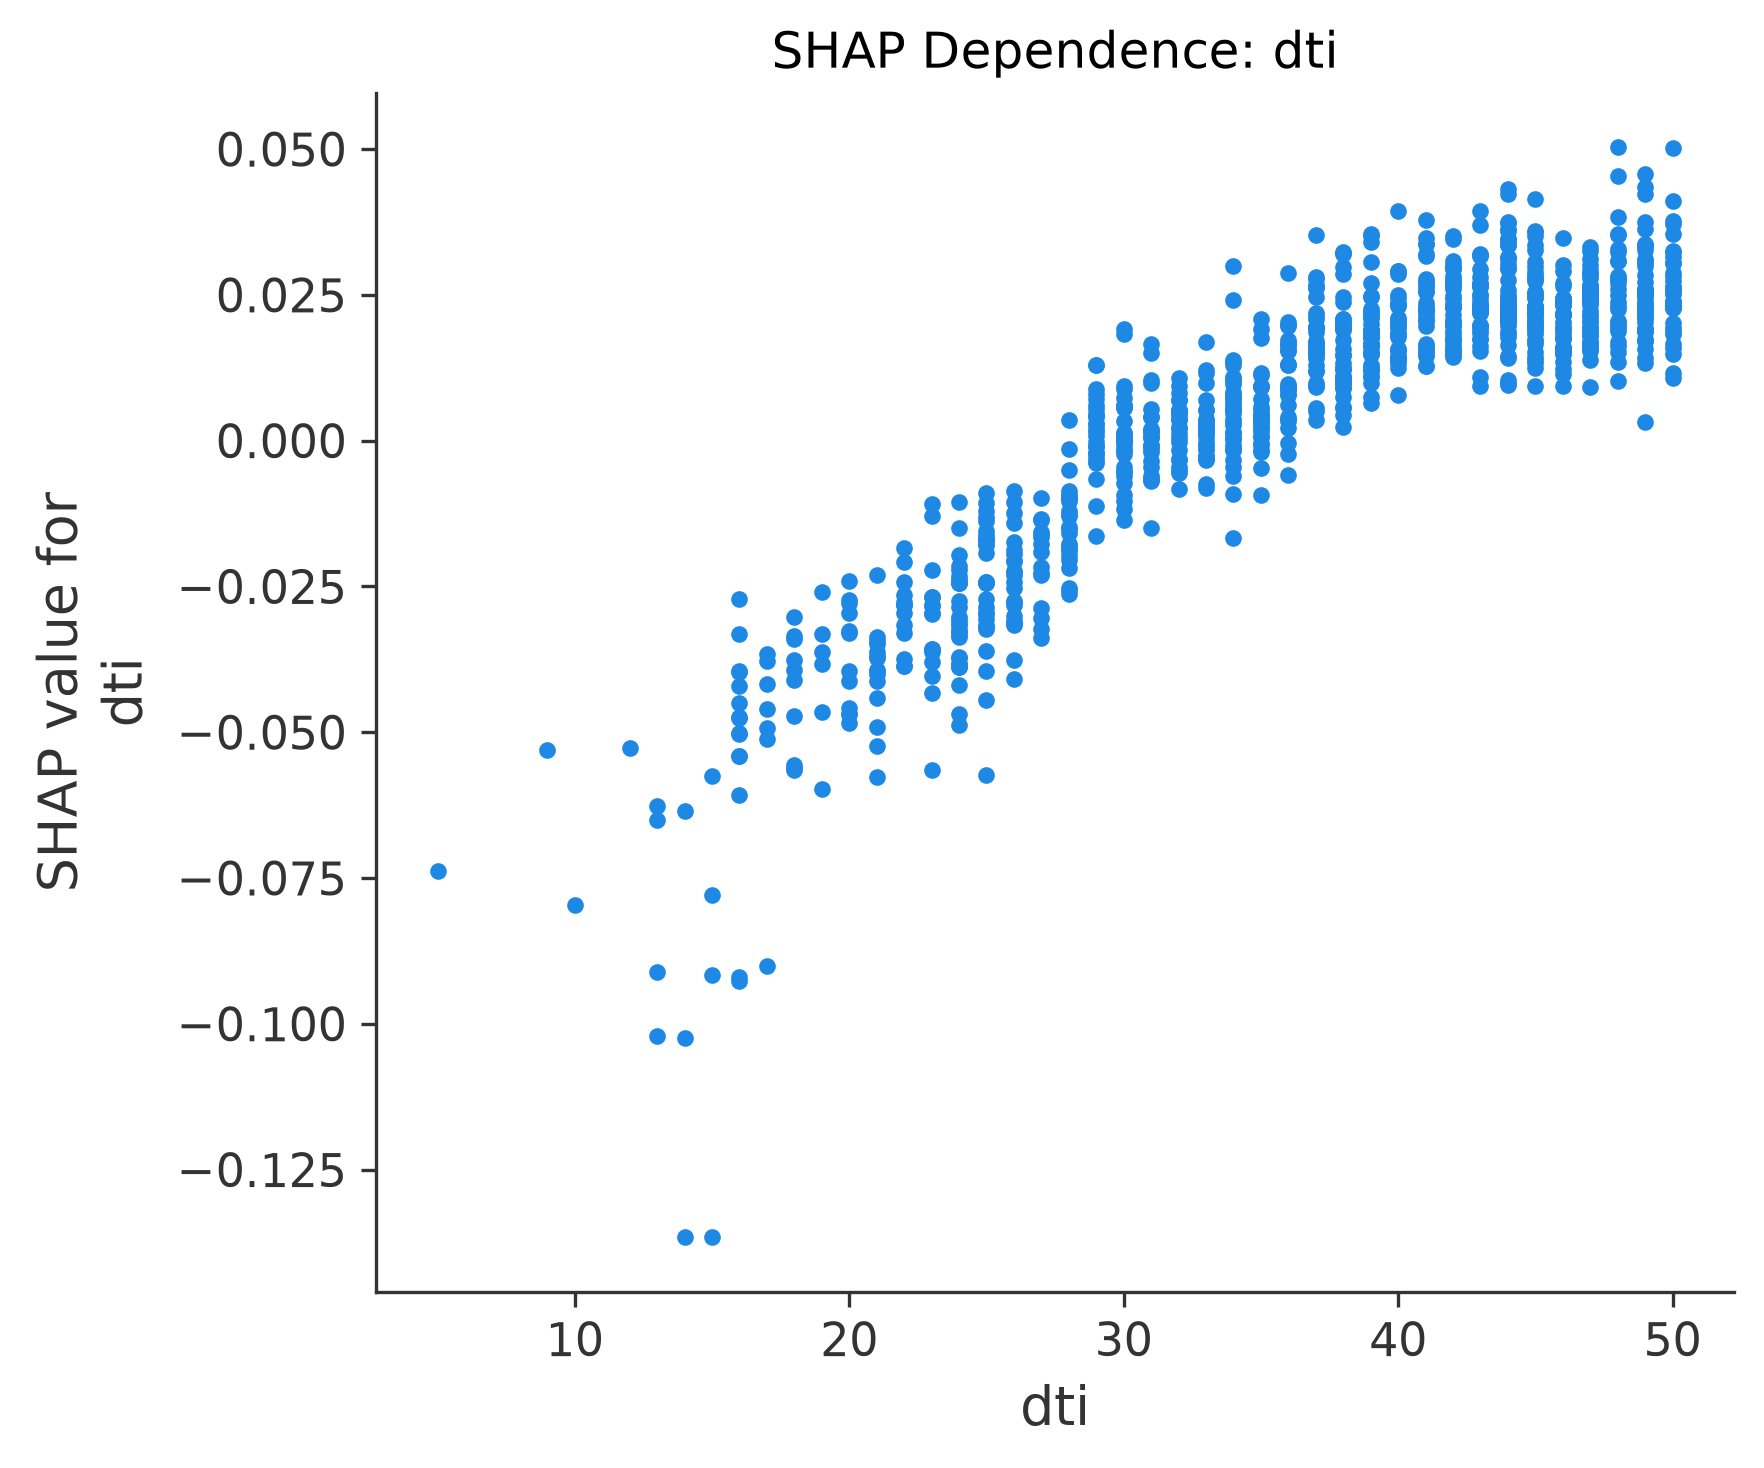

In [24]:
from IPython.display import display, Image

features = [
    "borrower_credit_score",
    "ph_prior_24m_delinquency",
    "loan_age",
    "dti"
]

for feature in features:
    path = FIGURES_DIR / f"shap_dependence_{feature}.png"

    if path.exists():
        print("\n", feature)
        display(Image(filename=str(path)))

In [25]:
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt
import os

pdf_path = FIGURES_DIR / "SHAP_Four_Feature_Dependence_Analysis.pdf"

with PdfPages(pdf_path) as pdf:

    for feature in features:

        path = FIGURES_DIR / f"shap_dependence_{feature}.png"

        if path.exists():

            img = plt.imread(path)

            fig, ax = plt.subplots(figsize=(11, 8))
            ax.imshow(img)
            ax.axis("off")
            ax.set_title(
                f"SHAP Dependence Analysis: {feature}",
                fontsize=14
            )

            pdf.savefig(fig, bbox_inches="tight")
            plt.close(fig)

print("PDF CREATED:", pdf_path)

PDF CREATED: C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning\figures\shap\SHAP_Four_Feature_Dependence_Analysis.pdf
